In [19]:
import subprocess
import sys

def install_if_needed(packages):
    for package in packages:
        try:
            __import__(package)
        except ImportError:
            print(f"Instalando {package}...")
            subprocess.check_call([sys.executable, "-m", "pip", "install", package])

packages = [
    "numpy", "librosa", "matplotlib", "seaborn", "ipywidgets", "soundfile", "IPython"
]

install_if_needed(packages)

# Verificar que las importaciones funcionan
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
import soundfile as sf
import math
from IPython.display import display

print("Todas las librerías están instaladas y listas para usarse.")


Todas las librerías están instaladas y listas para usarse.


In [20]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual, IntSlider
import soundfile as sf
import math

In [21]:
def fourierizer_1(file_1, file_2, F_s, w_len_1, w_len_2, hop_1, hop_2):
    """
    Aplica la transformada de Fourier de tiempo corto a dos archivos de audio y genera sus espectrogramas.

    Parámetros:
    file_1: str - Ruta al archivo de audio 1 (WAV o MP3).
    file_2: str - Ruta al archivo de audio 2 (WAV o MP3).
    F_s: int - Frecuencia de muestreo en Hertz para los dos archivos.
    w_len_1: int - Tamaño de las ventanas de muestreo para el archivo 1.
    w_len_2: int - Tamaño de las ventanas de muestreo para el archivo 2.
    hop_1: int - Tamaño del salto (en número de muestras) entre ventanas para el archivo 1.
    hop_2: int - Tamaño del salto (en número de muestras) entre ventanas para el archivo 2.

    Devuelve:
    list - Vector donde los primeros dos elementos son las matrices de Fourier de tiempo corto de los archivos,
           el tercer elemento es la frecuencia de muestreo utilizada,
           el cuarto y el quinto elemento son los tamaños de ventana utilizados,
           y el sexto y el séptimo elemento son los tamaños de salto utilizados.
    """
    sns.set_theme()

    # Cargar los archivos de audio seleccionados
    audio_1, sr_1 = librosa.load(file_1, sr=F_s)
    audio_2, sr_2 = librosa.load(file_2, sr=F_s)

    # Calcular matrices de coeficientes de transformada de Fourier de tiempo corto para cada archivo
    stft_1 = librosa.stft(audio_1, n_fft=w_len_1, hop_length=hop_1)
    stft_2 = librosa.stft(audio_2, n_fft=w_len_2, hop_length=hop_2)

    # Calcular intensidad de los coeficientes en cada ventana para cada frecuencia presente
    magnitude_1 = np.abs(stft_1)
    magnitude_2 = np.abs(stft_2)

# Creación de espectrogramas:

    plt.figure(figsize=(12, 6))

    # Espectrograma del archivo 1
    plt.subplot(1, 2, 1)
    librosa.display.specshow(
        librosa.amplitude_to_db(magnitude_1, ref=np.max),
        sr=F_s,
        hop_length=hop_1,
        x_axis='time',
        y_axis='log',
        cmap='coolwarm'
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("Espectrograma del archivo 1")

    # Espectrograma del archivo 2
    plt.subplot(1, 2, 2)
    librosa.display.specshow(
        librosa.amplitude_to_db(magnitude_2, ref=np.max),
        sr=F_s,
        hop_length=hop_2,
        x_axis='time',
        y_axis='log',
        cmap='coolwarm'
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("Espectrograma del archivo 2")

    plt.tight_layout()
    plt.show()

    X = [stft_1, stft_2, F_s, w_len_1, w_len_2, hop_1, hop_2]
    # Regresar las matrices de coeficientes de Fourier de tiempo corto de cada archivo y los parámetros usados
    return X

In [22]:
def replicator(matrix, rep, group_size, axis):
    """
    Repite 'rep' veces los elementos de las filas o las columnas según sea indicado (axis)
    Agrupa elementos consecutivos en grupos de tamaño 'group_size'
    Calcula una matriz donde los elementos son los promedios de cada grupo.
    Si el número total de elementos no es múltiplo de group_size, se truncan los sobrantes.
    """
  # Repetir los elementos de las filas/columnas las veces indicadas
    # Repetición
    repeated = np.repeat(matrix, rep, axis=axis)
    # Número de elementos finales en el eje donde se hicieron las repeticiones
    n = repeated.shape[axis]
    # Número de grupos completos
    n_groups = n // group_size

  # Truncar los elementos del grupo incompleto (de existir)
    slicer = [slice(None)] * repeated.ndim
    slicer[axis] = slice(0, n_groups * group_size)
    repeated = repeated[tuple(slicer)]

  # Reorganizar la matriz truncada para agrupar
    new_shape = list(repeated.shape)
    # Separar las filas/columnas en (n_groups, group_size)
    new_shape = new_shape[:axis] + [n_groups, group_size] + new_shape[axis+1:]
    # Agrupación de los elementos
    repeated_reshaped = repeated.reshape(new_shape)

  # Promediar los grupos
    replicated = repeated_reshaped.mean(axis=axis+1)
    return replicated

In [23]:
def aligner(m1, m2, axis):
    """
    Compara dos matrices m1 y m2 en las filas o columnas, según se indique (axis).
    Si tienen distinto número de filas/columnas, se identifica la de menor número
    Se hace un remuestreo para igualar al número de filas/columnas de la otra matriz.
    Para hacer este remuestreo:

    1. Se calcula el máximo común divisor (mcd) de los números de elementos;
    2. Se definen el número de repeticiones y el tamaño de los grupos como
      - rep = (elementos_en_matriz_mayor // mcd)
      - group_size = (elementos_en_matriz_menor // mcd)
    3. Se transforma la matriz que tiene menos elementos usando la función transform_along_axis.
    4. Se devuelve (m1_transformada, m2_transformada, (rep, group_size))
       (si no se requirió transformación, se devuelve (m1, m2, None))
    """
  # Comparación de las matrices en la dimensión especificada
    # Calcular dimensión de cada matriz
    n1 = m1.shape[axis]
    n2 = m2.shape[axis]
    # Comparar tamaños
    # Calcular mcd, número de repeticiones y tamaño de grupos de ser necesario
    # Regresar matrices y parámetros utilizados para la transformación si fue necesaria
    if n1 == n2:
        return m1, m2, None
    elif n1 < n2:
        d = math.gcd(n1, n2)
        rep = n2 // d
        group_size = n1 // d
        m1_trans = replicator(m1, rep, group_size, axis)
        return m1_trans, m2, (rep, group_size)
    else:
        d = math.gcd(n2, n1)
        rep = n1 // d
        group_size = n2 // d
        m2_trans = replicator(m2, rep, group_size, axis)
        return m1, m2_trans, (rep, group_size)

In [24]:
def resize_stft(stft_1, stft_2, F_s, w_len_1, w_len_2, hop_1, hop_2):
    """
    Recibe dos matrices de coeficientes STFT (stft_1 y stft_2),
    la frecuencia de muestreo F_s con la que se muestrearon ambas
    y sus respectivos tamaños de ventana (w_len_1, w_len_2) y tamaños de salto (hop_1, hop_2).

    Con esta información:
      1. Se calculan las dimensiones de cada matriz y la duración (en segundos) del sonido correspondiente.
      2. Se alinean las matrices en la dimensión del tiempo (columnas):
         - Se determina cuál de los dos sonidos tiene menor duración.
         - Se separa la matriz del sonido más largo en dos partes: la primera abarca la duración
           del sonido más corto y la segunda el resto.
      3. Se remuestrean los coeficientes en la dimensión del tiempo de ser necesario:
         - se compara el número de columnas de la matriz correspondiente al sonido corto y la submatriz alineada del sonido largo.
         - se aplica el proceso de repetición y agrupación (usando el mcd) a la que tenga menos columnas.
      4. Se remuestrean los coeficientes en la dimensión de la frecuencia (sin alterar el rango) de ser necesario.
      5. Si la matriz del sonido más largo fue modificada en la parte alineada, se aplica la misma
         transformación a la submatriz restante y se concatenan.

    Regresa una lista [stft_1_final, stft_2_final] que puede corresponder a las matrices originales
    o a sus versiones transformadas.
    """
  # Dimensiones y duración
    rows1, cols1 = stft_1.shape
    rows2, cols2 = stft_2.shape
    duration1 = ((cols1 - 1) * hop_1 + w_len_1) / F_s
    duration2 = ((cols2 - 1) * hop_2 + w_len_2) / F_s
    print("Dimensiones de la matriz 1: ", rows1, ", ", cols1)
    print("Dimensiones de la matriz 2: ", rows2, ", ", cols2)
    print("Duración del sonido 1: ", duration1, "segundos")
    print("Duración del sonido 2: ", duration2, "segundos")


  # Determinar cuál es el sonido más corto y separar la matriz más larga
    if duration1 < duration2:
        short_sound = 1
        stft_short = stft_1.copy()
        stft_long = stft_2.copy()
        hop_long = hop_2
    elif duration2 < duration1:
        short_sound = 2
        stft_short = stft_2.copy()
        stft_long = stft_1.copy()
        hop_long = hop_1
    else:
        short_sound = None
        stft_short = stft_1.copy()
        stft_long = stft_2.copy()

    print("Sonido más corto: ", short_sound)

    if short_sound is not None:
        target_duration = min(duration1, duration2)
        # Número de columnas de la matriz del sonido más largo que se ajustan a target_duration.
        # Se asume que cada columna representa (hop_long / F_s) segundos.
        N_aligned = int(np.floor(target_duration / (hop_long / F_s)))
        stft_long_aligned = stft_long[:, :N_aligned]
        stft_long_remainder = stft_long[:, N_aligned:]
        print("Número de columnas en el corte: ", N_aligned)
    else:
        stft_long_aligned = stft_long
        stft_long_remainder = None

    # Asignar las dos matrices a comparar en el eje temporal:
    # Se comparan la matriz del sonido corto y la parte alineada del sonido largo.
    if short_sound == 1:
        # stft_1 es corto y stft_2 es largo
        m_time_1 = stft_short       # sonido corto (stft_1)
        m_time_2 = stft_long_aligned  # parte alineada de stft_2
    elif short_sound == 2:
        # stft_2 es corto y stft_1 es largo
        m_time_1 = stft_long_aligned  # parte alineada de stft_1
        m_time_2 = stft_short         # sonido corto (stft_2)
    else:
        m_time_1 = stft_1
        m_time_2 = stft_2

  # Alinear las columnas (eje 1) usando align_axis
    m_time_1_aligned, m_time_2_aligned, col_params = aligner(m_time_1, m_time_2, axis=1)
    print("Dimensiones de la matriz alineada 1: ", m_time_1_aligned.shape)
    print("Dimensiones de la matriz alineada 2: ", m_time_2_aligned.shape)
    # Determinar cuál de las dos matrices fue modificada en columnas:
    if col_params is None:
        col_modified = None
    else:
        if m_time_1.shape[1] < m_time_2.shape[1]:
            modified_sound = 1
        else:
            modified_sound = 2
        col_modified = modified_sound

    print("Matriz modificada en columnas: ", col_modified)

    # Reasignar las matrices alineadas a cada sonido según quién es corto y quién es largo.
    if short_sound == 1:
        final_time_short = m_time_1_aligned   # stft_1 (corto)
        final_time_long_aligned = m_time_2_aligned  # parte alineada de stft_2
    elif short_sound == 2:
        final_time_short = m_time_2_aligned   # stft_2 (corto)
        final_time_long_aligned = m_time_1_aligned  # parte alineada de stft_1
    else:
        final_time_short = m_time_1_aligned
        final_time_long_aligned = m_time_2_aligned

  # Alinear las filas de las matrices resultantes
    if final_time_short.shape[0] < final_time_long_aligned.shape[0]:
        row_modified = 2 if short_sound == 2 else 1
    elif final_time_short.shape[0] > final_time_long_aligned.shape[0]:
        row_modified = 1 if short_sound == 2 else 2
    else:
        row_modified = None

    final_time_short, final_time_long_aligned, row_params = aligner(final_time_short, final_time_long_aligned, axis=0)


    print("Matriz modificada en filas: ", row_modified)

    print("Dimensiones de la matriz final 1: ", final_time_short.shape)
    print("Dimensiones de la matriz final 2: ", final_time_long_aligned.shape)

  # Reensamblar la matriz del sonido largo:
    # Si se tuvo que separar la matriz del sonido más largo y, además, éste fue modificado
    # en el proceso (por columnas y/o filas), se aplica la misma transformación a la parte restante.
    if stft_long_remainder is not None:
        # Para columnas: aplicar la transformación si la matriz del sonido largo fue la que se
        # transformó en el proceso de alineación temporal.
        if short_sound == 1:
            # En este caso, stft_2 es el sonido largo.
            if col_modified == 2:
                stft_long_remainder = replicator(stft_long_remainder, col_params[0], col_params[1], axis=1)
        elif short_sound == 2:
            if col_modified == 1:
                stft_long_remainder = replicator(stft_long_remainder, col_params[0], col_params[1], axis=1)
        # Para filas: si el sonido largo fue transformado en el eje de filas, aplicar la misma transformación.
        if short_sound == 1:
            if row_modified == 2:
                stft_long_remainder = replicator(stft_long_remainder, row_params[0], row_params[1], axis=0)
        elif short_sound == 2:
            if row_modified == 1:
                stft_long_remainder = replicator(stft_long_remainder, row_params[0], row_params[1], axis=0)
        # Finalmente, concatenar la parte alineada transformada y la parte restante transformada.
        final_long = np.concatenate([final_time_long_aligned, stft_long_remainder], axis=1)
        final_short = final_time_short

    else:
        # No hubo parte restante.
        if short_sound == 1:
            final_short = final_time_short   # stft_1 (corto)
            final_long = final_time_long_aligned  # stft_2 (largo)
        elif short_sound == 2:
            final_short = final_time_short   # stft_2 (corto)
            final_long = final_time_long_aligned  # stft_1 (largo)
        else:
            final_short = final_time_short
            final_long = final_time_long_aligned

    # Reubicar las matrices según corresponda a sonido 1 y sonido 2:
    if short_sound == 1:
        stft1_final = final_short
        stft2_final = final_long
    elif short_sound == 2:
        stft1_final = final_long
        stft2_final = final_short
    else:
        stft1_final = final_short
        stft2_final = final_long

    return [stft1_final, stft2_final]

In [25]:
def trim_zero_columns(matrix):
    """
    Recibe una matriz y devuelve una submatriz que contiene solo las columnas
    que tienen al menos un elemento distinto de cero. Se eliminan las columnas de ceros
    que se encuentran al principio y al final de la matriz.

    Parámetros:
    matrix : np.ndarray
        Matriz de entrada.

    Retorna:
    np.ndarray
        Submatriz recortada.
    """
    # Genera un array booleano: cada posición es True si la columna tiene al menos un elemento distinto de 0.
    cols_with_data = np.any(matrix != 0, axis=0)

    # Obtiene los índices de las columnas que contienen algún dato.
    indices = np.where(cols_with_data)[0]

    # Si no hay columnas con datos, retorna una matriz vacía con el mismo número de filas.
    if indices.size == 0:
        return np.empty((matrix.shape[0], 0), dtype=matrix.dtype)

    # Define el primer y último índice de columna con datos.
    first_idx = indices[0]
    last_idx = indices[-1] + 1  # +1 para incluir la última columna con datos

    # Retorna la submatriz que va desde la primera hasta la última columna con datos.
    return matrix[:, first_idx:last_idx]

In [26]:
def fourierizer_2(sound_name, stft_1, stft_2, F_s, w_len_1, w_len_2, hop_1, hop_2, start_1, start_2, duration_1, duration_2, min_freq_1, min_freq_2, max_freq_1, max_freq_2):
    """
    Selecciona regiones específicas de las matrices de coeficientes de Fourier y realiza operaciones adicionales.

    Parámetros:
    sound_name: Nombre con el que se desea guardar el sonido resultante
    stft_1, stft_2: Matrices de coeficientes de Fourier de los dos archivos.
    w_len_1, w_len_2: Tamaños de ventana de muestreo para cada archivo.
    hop_1, hop_2: Tamaños de salto entre ventanas para cada archivo.
    start_1, start_2: Inicio en segundos para la selección temporal.
    duration_1, duration_2: Duración en segundos para la selección temporal.
    min_freq_1, min_freq_2: Frecuencia mínima seleccionada para cada archivo.
    max_freq_1, max_freq_2: Frecuencia máxima seleccionada para cada archivo.
    F_s: Frecuencia de muestreo.

    Retorna:
    None
    """
    # Convertir tiempos y frecuencias a índices
    start_idx_1 = int(start_1 * F_s / hop_1)
    start_idx_2 = int(start_2 * F_s / hop_2)
    end_idx_1 = start_idx_1 + int(duration_1 * F_s / hop_1)
    end_idx_2 = start_idx_2 + int(duration_2 * F_s / hop_2)

    min_bin_1 = int(min_freq_1 * w_len_1 / F_s)
    max_bin_1 = int(max_freq_1 * w_len_1 / F_s)
    min_bin_2 = int(min_freq_2 * w_len_2 / F_s)
    max_bin_2 = int(max_freq_2 * w_len_2 / F_s)

    # Crear máscaras para las selecciones
    selected_1 = np.zeros_like(stft_1, dtype=complex)
    selected_2 = np.zeros_like(stft_2, dtype=complex)

    selected_1[min_bin_1:max_bin_1, start_idx_1:end_idx_1] = stft_1[min_bin_1:max_bin_1, start_idx_1:end_idx_1]
    selected_2[min_bin_2:max_bin_2, start_idx_2:end_idx_2] = stft_2[min_bin_2:max_bin_2, start_idx_2:end_idx_2]

    # Mostrar espectrogramas con selecciones
    sns.set_theme()
    plt.figure(figsize=(12, 6))

    # Espectrograma del archivo 1 con selección
    plt.subplot(1, 2, 1)
    librosa.display.specshow(
        librosa.amplitude_to_db(np.abs(stft_1), ref=np.max),
        sr=F_s,
        hop_length=hop_1,
        x_axis='time',
        y_axis='log',
        cmap='coolwarm'
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("Selección en el espectrograma del archivo 1")
    plt.gca().add_patch(plt.Rectangle(
        (start_idx_1 * hop_1 / F_s, min_freq_1),
        duration_1,
        max_freq_1 - min_freq_1,
        edgecolor='red',
        fill=False,
        lw=2
    ))

    # Espectrograma del archivo 2 con selección
    plt.subplot(1, 2, 2)
    librosa.display.specshow(
        librosa.amplitude_to_db(np.abs(stft_2), ref=np.max),
        sr=F_s,
        hop_length=hop_2,
        x_axis='time',
        y_axis='log',
        cmap='coolwarm'
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("Selección en el espectrograma del archivo 2")
    plt.gca().add_patch(plt.Rectangle(
        (start_idx_2 * hop_2 / F_s, min_freq_2),
        duration_2,
        max_freq_2 - min_freq_2,
        edgecolor='red',
        fill=False,
        lw=2
    ))

    plt.tight_layout()
    plt.show()

    resized_1, resized_2 = resize_stft(selected_1,selected_2,F_s,w_len_1,w_len_2,hop_1,hop_2)

    # Crear nueva matriz combinada
    max_rows = max(resized_1.shape[0], resized_2.shape[0])
    max_cols = max(resized_1.shape[1], resized_2.shape[1])

    combined = np.zeros((max_rows, max_cols), dtype=complex)

    combined[:resized_1.shape[0], :resized_1.shape[1]] += resized_1
    combined[:resized_2.shape[0], :resized_2.shape[1]] += resized_2

    #eliminar todo lo que sea silencio y agarrar duración más larga de las selecciones
    combined_trimmed = trim_zero_columns(combined)

    duration_combined = max(duration_1,duration_2)
    N = combined_trimmed.shape[1]
    hop_eff = int((duration_combined * F_s) / N)

    # Transformada inversa de Fourier
    combined_istft = librosa.istft(combined_trimmed, hop_length = hop_eff)

    # Espectrograma de la matriz combinada
    plt.figure(figsize=(6, 6))
    librosa.display.specshow(
        librosa.amplitude_to_db(np.abs(combined_trimmed), ref=np.max),
        sr=F_s,
        hop_length=hop_eff,
        x_axis='time',
        y_axis='log',
        cmap='coolwarm'
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("Espectrograma de la matriz combinada")
    plt.show()

    output_name = sound_name + '.wav'

    # Guardar el archivo de audio generado
    sf.write(output_name, combined_istft, int(F_s))
    print("Archivo de audio generado" + output_name)

In [27]:
# Archivos de prueba

path = 'C:\\Users\\polo_\\Documents\\Tesis\\Muestras\\Documentadas\\'
kick_distorted = path + 'Kick Distorsionado.wav'
kick_acoustic = path + 'Kick Acústico.wav'
snare_agressive = path + 'Snare Agresivo.wav'
snare_high = path + 'Snare Agudo.wav'
lead_piano = path + 'Lead Piano.wav'
lead_synth = path + 'Lead Sintetizador.wav'
pad_low = path + 'Pad Grave.wav'
pad_high = path + 'Pad Tranquilo.wav'
pluck_bell = path + 'Pluck Campana.wav'
pluck_synth = path + 'Pluck Sintetizador.wav'

# Pruebas
En esta sección se encuentra cada uno de los ejemplos mostrados en el documento listos para su ejecución. Se pueden modificar los parámetros para hacer variaciones de los resultados finales

## Ejemplo 1: Kick Acústico X Kick Distorsionado



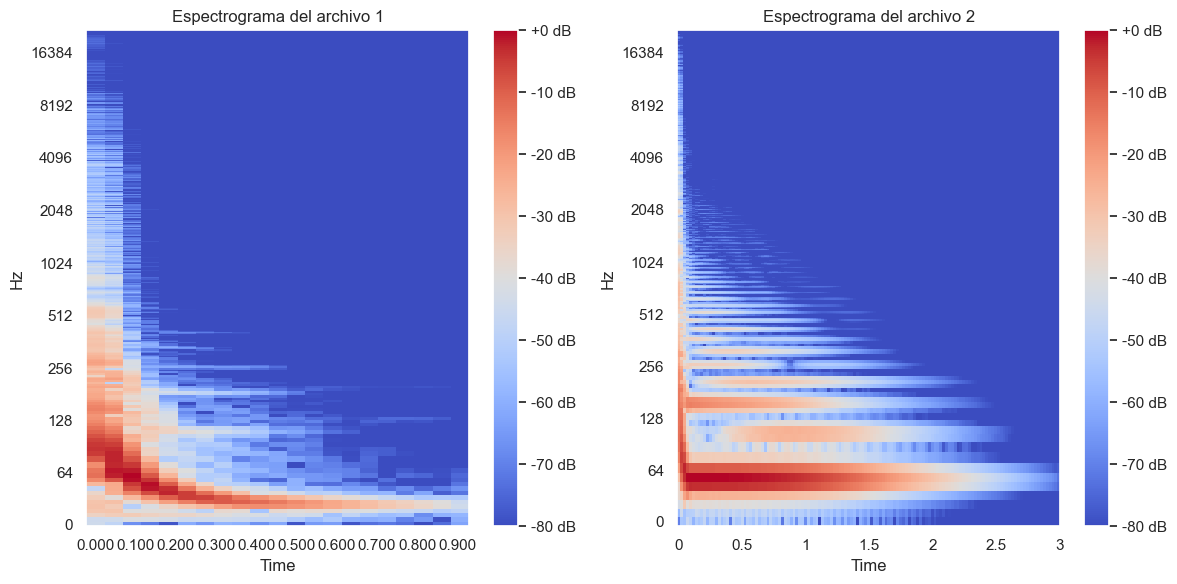

In [28]:
coefs_1 = fourierizer_1(kick_acoustic,kick_distorted,44100,8000,4000,2000,1000)

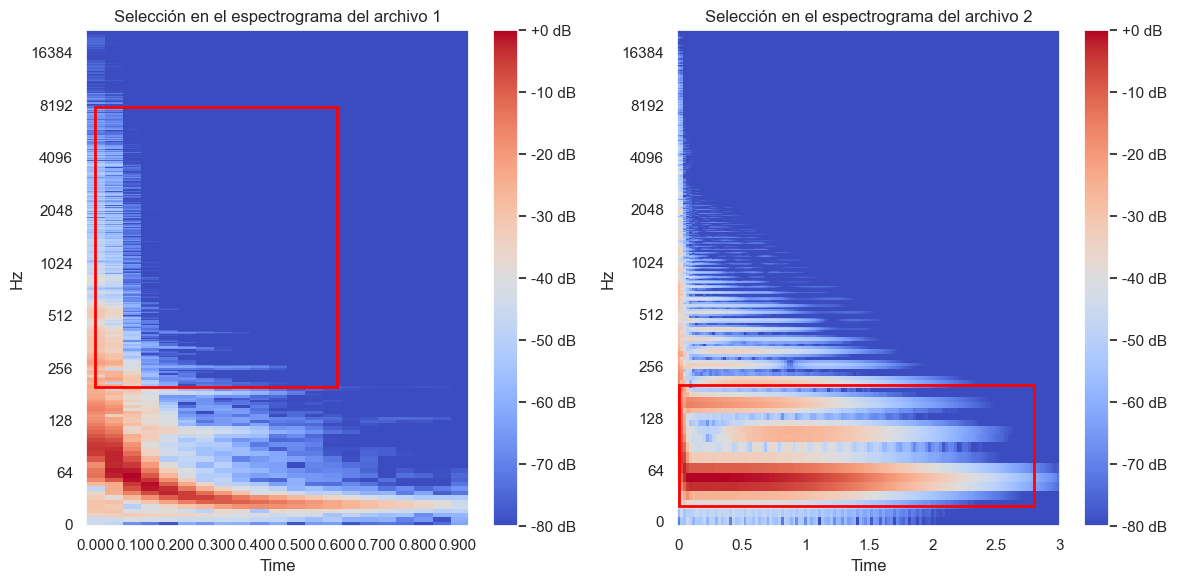

Dimensiones de la matriz 1:  4001 ,  21
Dimensiones de la matriz 2:  2001 ,  133
Duración del sonido 1:  1.08843537414966 segundos
Duración del sonido 2:  3.0839002267573696 segundos
Sonido más corto:  1
Número de columnas en el corte:  48
Dimensiones de la matriz alineada 1:  (4001, 48)
Dimensiones de la matriz alineada 2:  (2001, 48)
Matriz modificada en columnas:  1
Matriz modificada en filas:  2
Dimensiones de la matriz final 1:  (4001, 48)
Dimensiones de la matriz final 2:  (4001, 48)


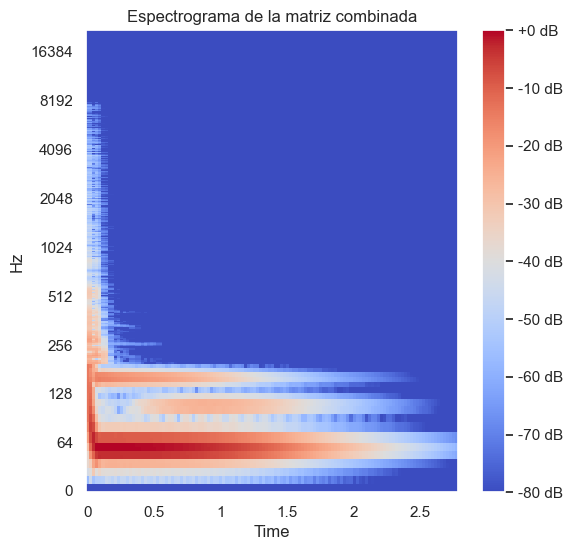

Archivo de audio generadofourierized kick.wav


In [29]:
fourierizer_2('fourierized kick', coefs_1[0], coefs_1[1], coefs_1[2], coefs_1[3], coefs_1[4], coefs_1[5], coefs_1[6], 0, 0, 0.6, 2.8, 200, 20, 8000, 200)

## Ejemplo 2: Piano X Sintetizador



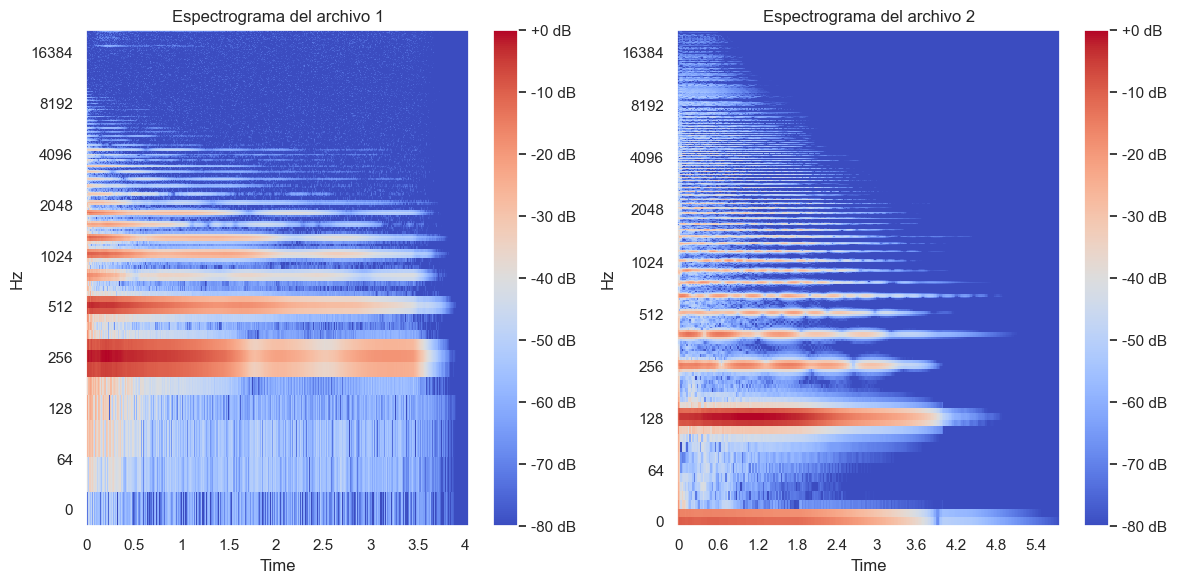

In [13]:
coefs_2 = fourierizer_1(lead_piano,lead_synth,44100,1000,4000,250,1000)

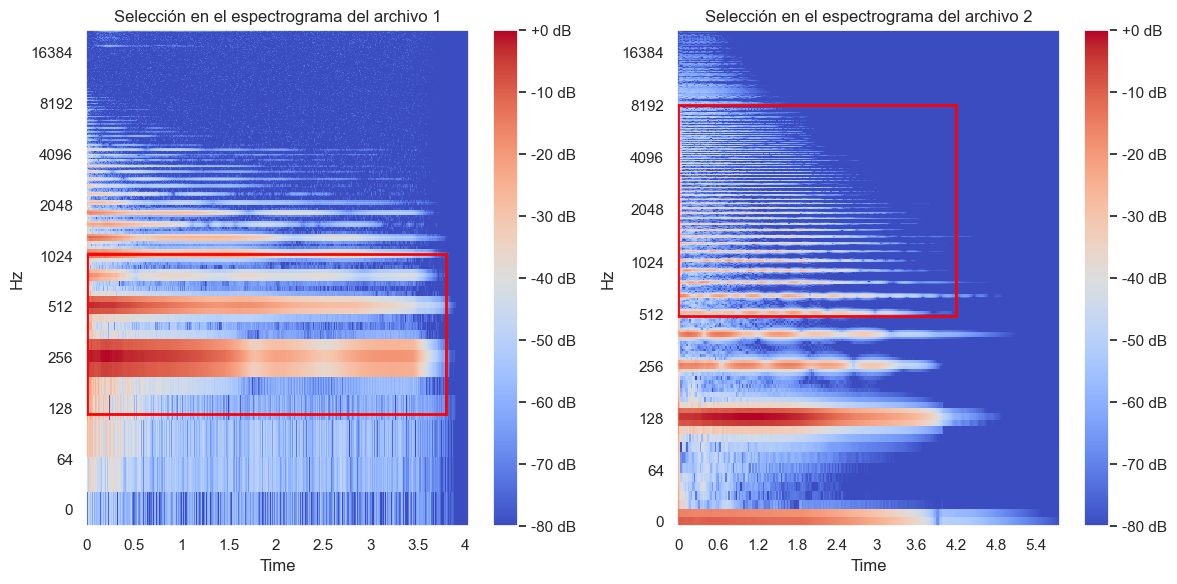

Dimensiones de la matriz 1:  501 ,  714
Dimensiones de la matriz 2:  2001 ,  255
Duración del sonido 1:  4.0646258503401365 segundos
Duración del sonido 2:  5.850340136054422 segundos
Sonido más corto:  1
Número de columnas en el corte:  179
Dimensiones de la matriz alineada 1:  (501, 714)
Dimensiones de la matriz alineada 2:  (2001, 714)
Matriz modificada en columnas:  2
Matriz modificada en filas:  1
Dimensiones de la matriz final 1:  (2001, 714)
Dimensiones de la matriz final 2:  (2001, 714)


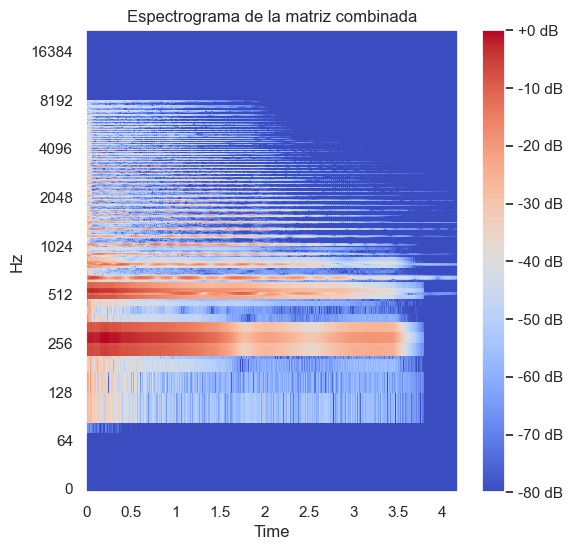

Archivo de audio generadofourierized lead.wav


In [14]:
fourierizer_2('fourierized lead', coefs_2[0], coefs_2[1], coefs_2[2], coefs_2[3], coefs_2[4], coefs_2[5], coefs_2[6], 0, 0, 3.8, 4.2, 120, 500, 1050, 8200)

## Ejemplo 3: Snare agresivo X Snare agudo

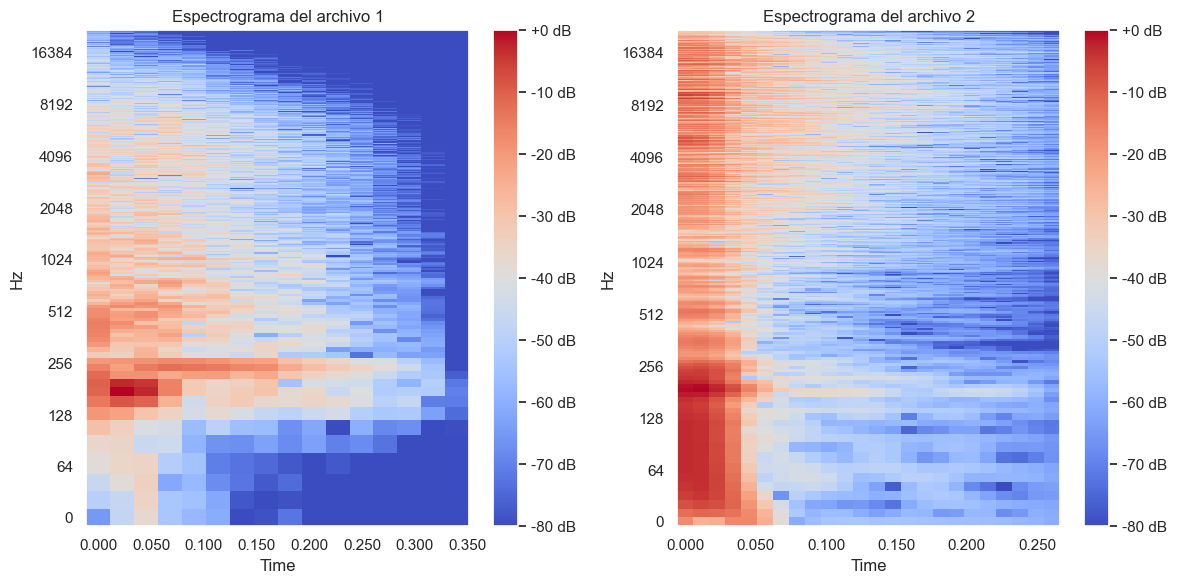

In [15]:
coefs_3 = fourierizer_1(snare_agressive,snare_high,44100,2000,4000,1000,500)

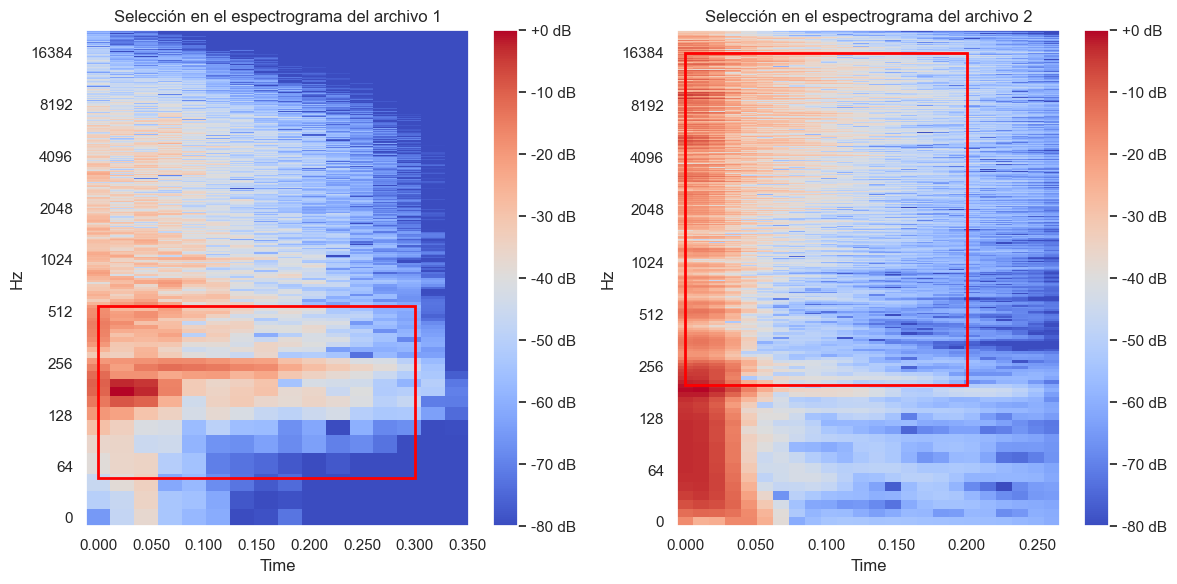

Dimensiones de la matriz 1:  1001 ,  16
Dimensiones de la matriz 2:  2001 ,  24
Duración del sonido 1:  0.3854875283446712 segundos
Duración del sonido 2:  0.35147392290249435 segundos
Sonido más corto:  2
Número de columnas en el corte:  15
Dimensiones de la matriz alineada 1:  (1001, 24)
Dimensiones de la matriz alineada 2:  (2001, 24)
Matriz modificada en columnas:  1
Matriz modificada en filas:  1
Dimensiones de la matriz final 1:  (2001, 24)
Dimensiones de la matriz final 2:  (2001, 24)


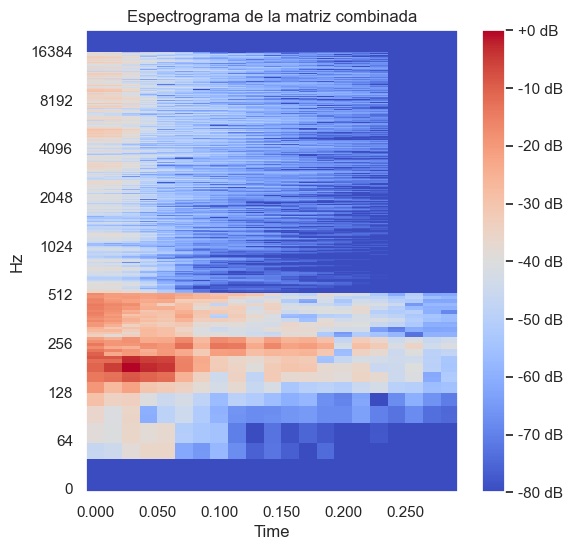

Archivo de audio generadofourierized snare.wav


In [16]:
fourierizer_2('fourierized snare', coefs_3[0], coefs_3[1], coefs_3[2], coefs_3[3], coefs_3[4], coefs_3[5], coefs_3[6], 0, 0, 0.3, 0.2, 50, 200, 550, 16300)

## Ejemplo 4: Pad grave X Pad tranquilo

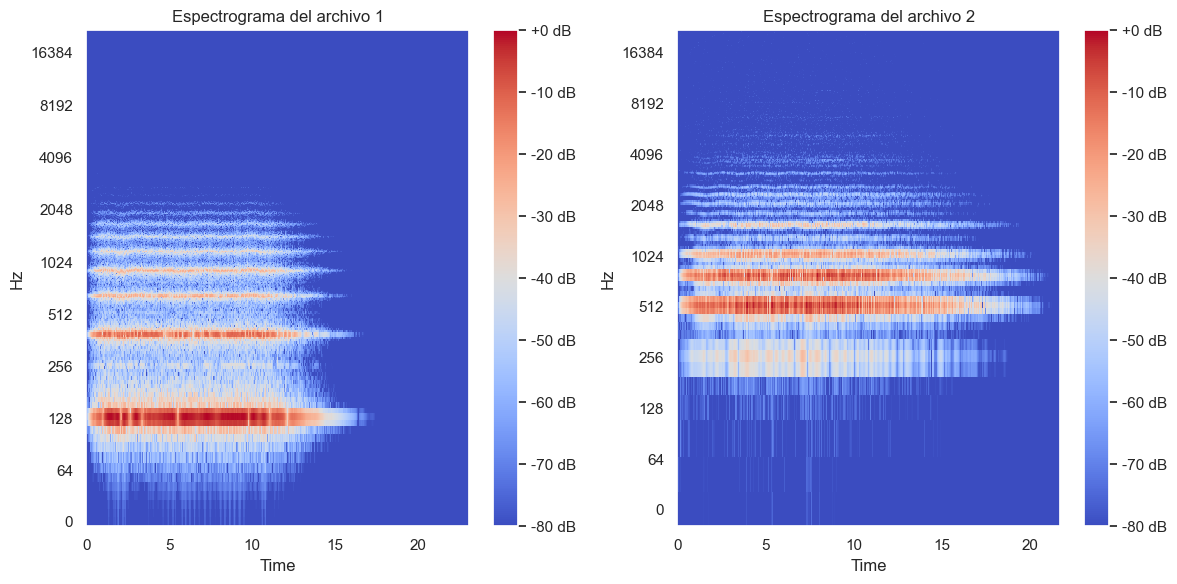

In [17]:
coefs_4 = fourierizer_1(pad_low,pad_high,44100,4000,1000,500,500)

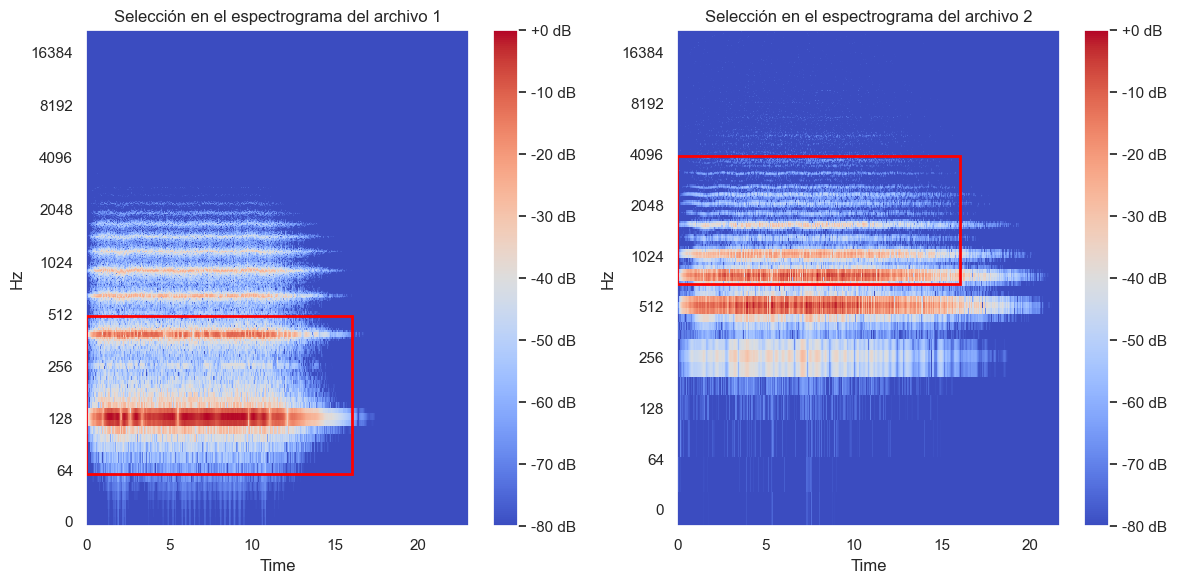

Dimensiones de la matriz 1:  2001 ,  2036
Dimensiones de la matriz 2:  501 ,  1914
Duración del sonido 1:  23.163265306122447 segundos
Duración del sonido 2:  21.71201814058957 segundos
Sonido más corto:  2
Número de columnas en el corte:  1915
Dimensiones de la matriz alineada 1:  (2001, 1915)
Dimensiones de la matriz alineada 2:  (501, 1915)
Matriz modificada en columnas:  2
Matriz modificada en filas:  2
Dimensiones de la matriz final 1:  (2001, 1915)
Dimensiones de la matriz final 2:  (2001, 1915)


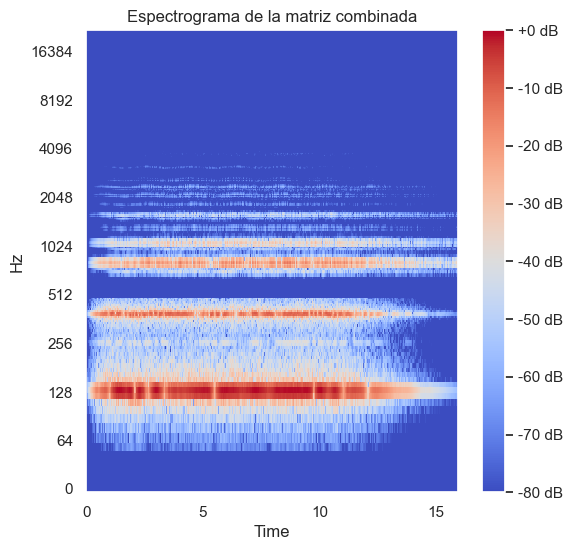

Archivo de audio generadofourierized pad.wav


In [18]:
fourierizer_2('fourierized pad', coefs_4[0], coefs_4[1], coefs_4[2], coefs_4[3], coefs_4[4], coefs_4[5], coefs_4[6], 0, 0, 16, 16, 60, 700, 500, 4000)

## Ejemplo 5: Pluck de Campana X Pluck de Sintetizador

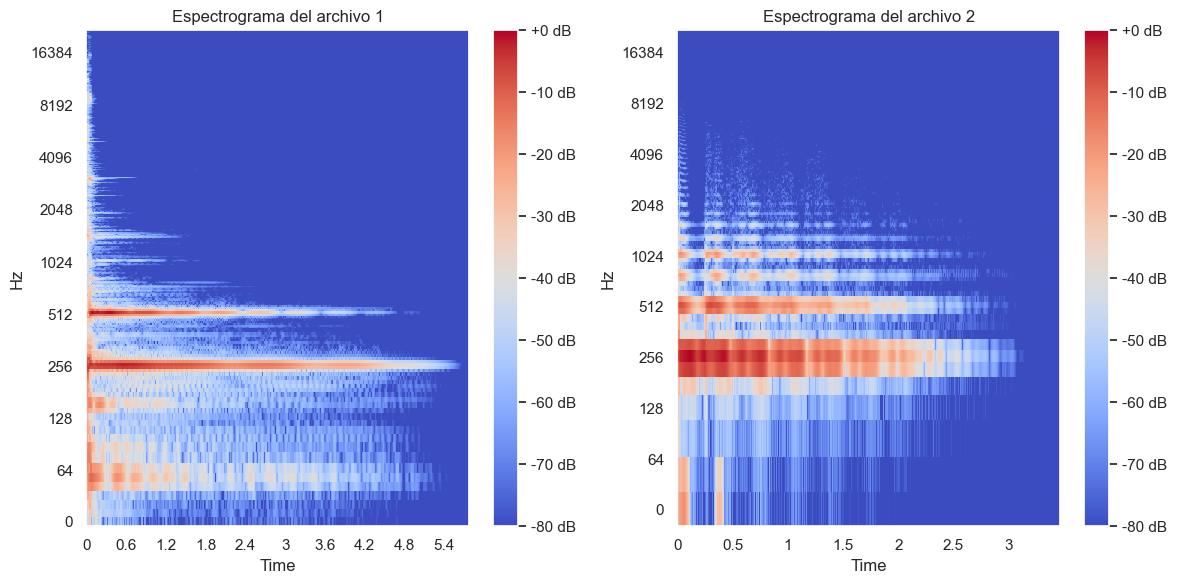

In [45]:
coefs_5 = fourierizer_1(pluck_bell,pluck_synth,44100,4000,1000,500,125)

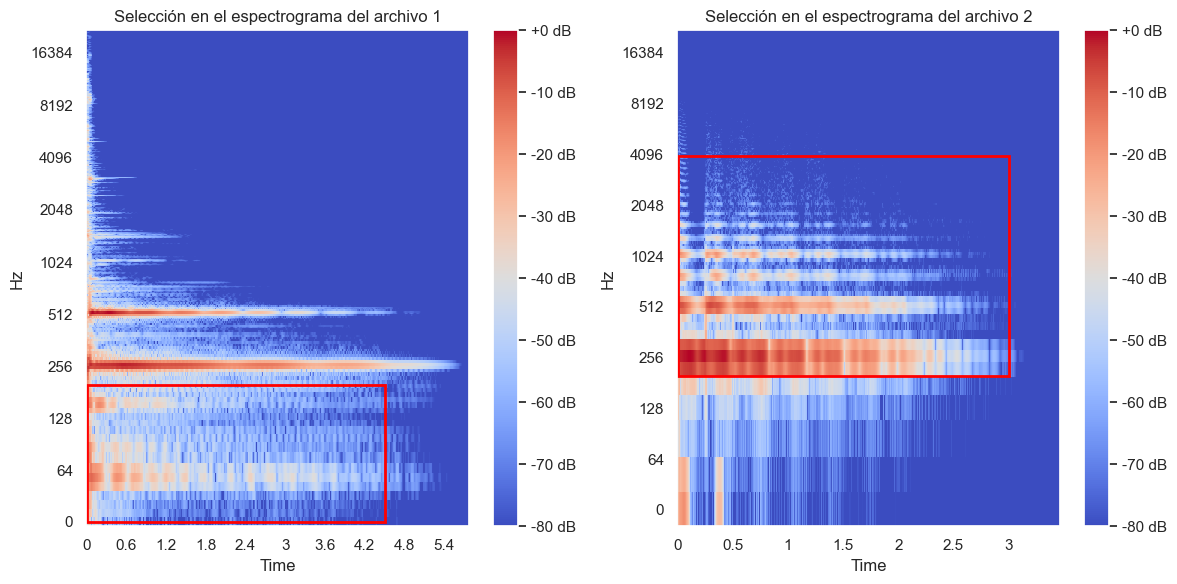

Dimensiones de la matriz 1:  2001 ,  510
Dimensiones de la matriz 2:  501 ,  1223
Duración del sonido 1:  5.861678004535148 segundos
Duración del sonido 2:  3.4863945578231292 segundos
Sonido más corto:  2
Número de columnas en el corte:  307
Dimensiones de la matriz alineada 1:  (2001, 1223)
Dimensiones de la matriz alineada 2:  (501, 1223)
Matriz modificada en columnas:  1
Matriz modificada en filas:  2
Dimensiones de la matriz final 1:  (2001, 1223)
Dimensiones de la matriz final 2:  (2001, 1223)


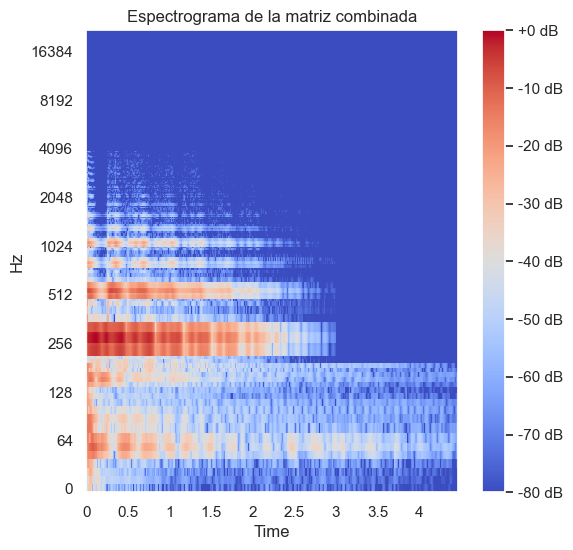

Archivo de audio generadofourierized pluck.wav


In [63]:
fourierizer_2('fourierized pluck', coefs_5[0], coefs_5[1], coefs_5[2], coefs_5[3], coefs_5[4], coefs_5[5], coefs_5[6], 0, 0, 4.5, 3.0, 0, 200, 200, 4000)

## Ejemplo 6: Kick Distorsionado X Lead Sintetizador

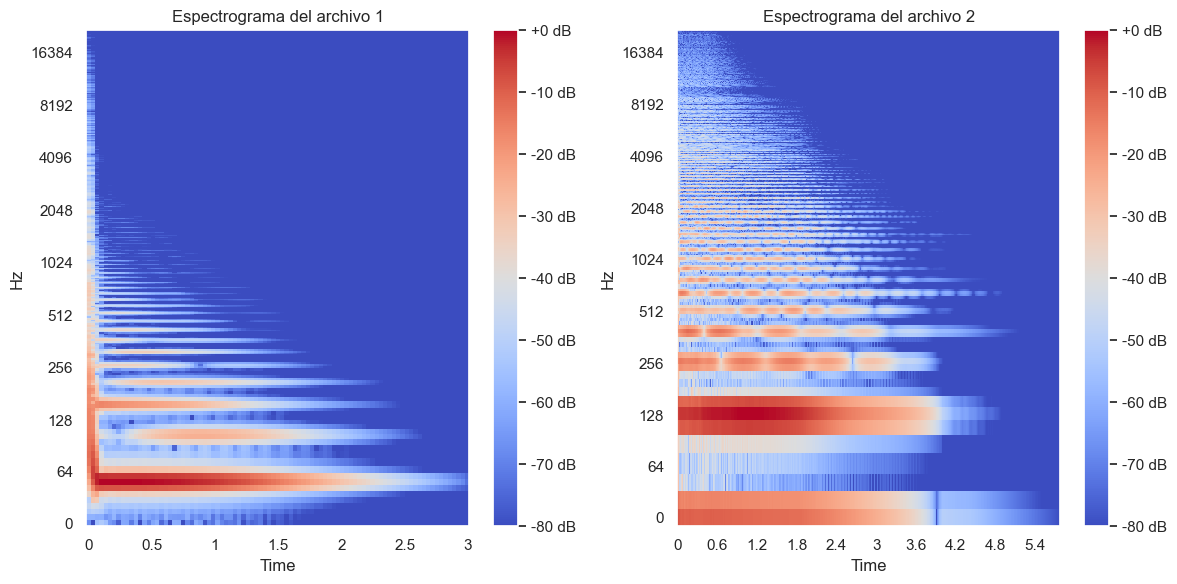

In [51]:
coefs_6 = fourierizer_1(kick_distorted,lead_synth,44100,6000,2000,1500,500)

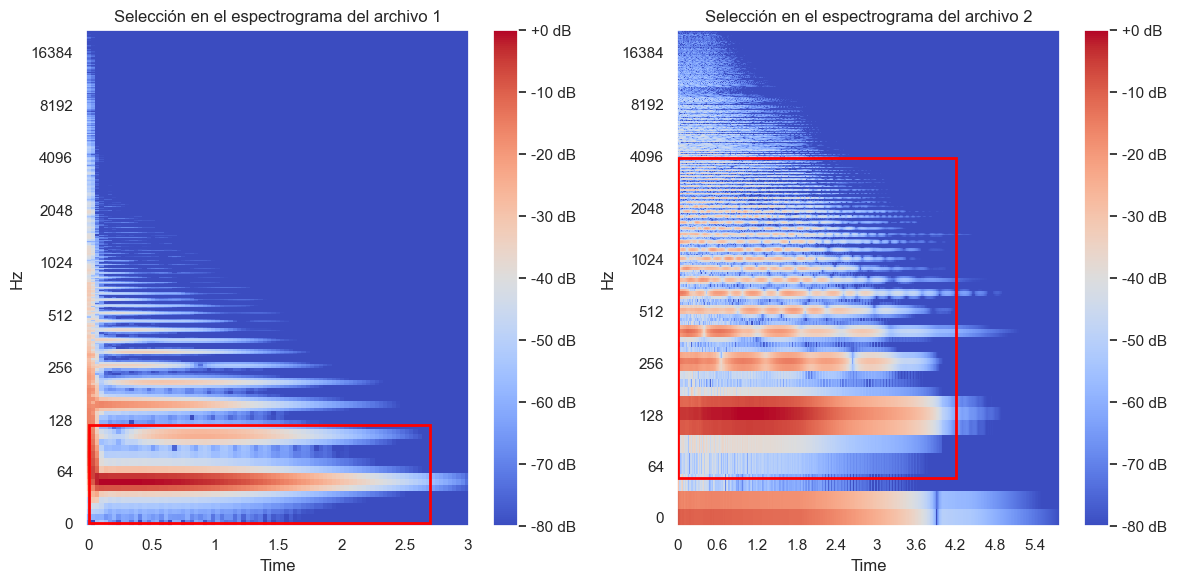

Dimensiones de la matriz 1:  3001 ,  89
Dimensiones de la matriz 2:  1001 ,  510
Duración del sonido 1:  3.129251700680272 segundos
Duración del sonido 2:  5.816326530612245 segundos
Sonido más corto:  1
Número de columnas en el corte:  276
Dimensiones de la matriz alineada 1:  (3001, 276)
Dimensiones de la matriz alineada 2:  (1001, 276)
Matriz modificada en columnas:  1
Matriz modificada en filas:  2
Dimensiones de la matriz final 1:  (3001, 276)
Dimensiones de la matriz final 2:  (3001, 276)


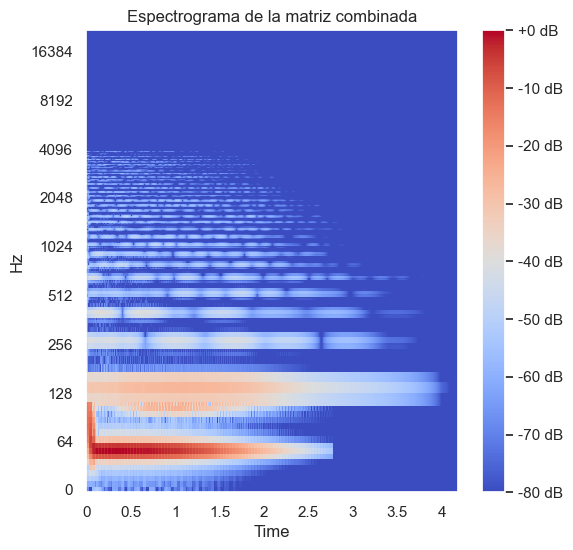

Archivo de audio generadofourierized kicksynth.wav


In [64]:
fourierizer_2('fourierized kicksynth', coefs_6[0], coefs_6[1], coefs_6[2], coefs_6[3], coefs_6[4], coefs_6[5], coefs_6[6], 0, 0, 2.7, 4.2, 0, 50, 120, 4000)

## Ejemplo 7: Pluck de Campana X Pad Tranquilo

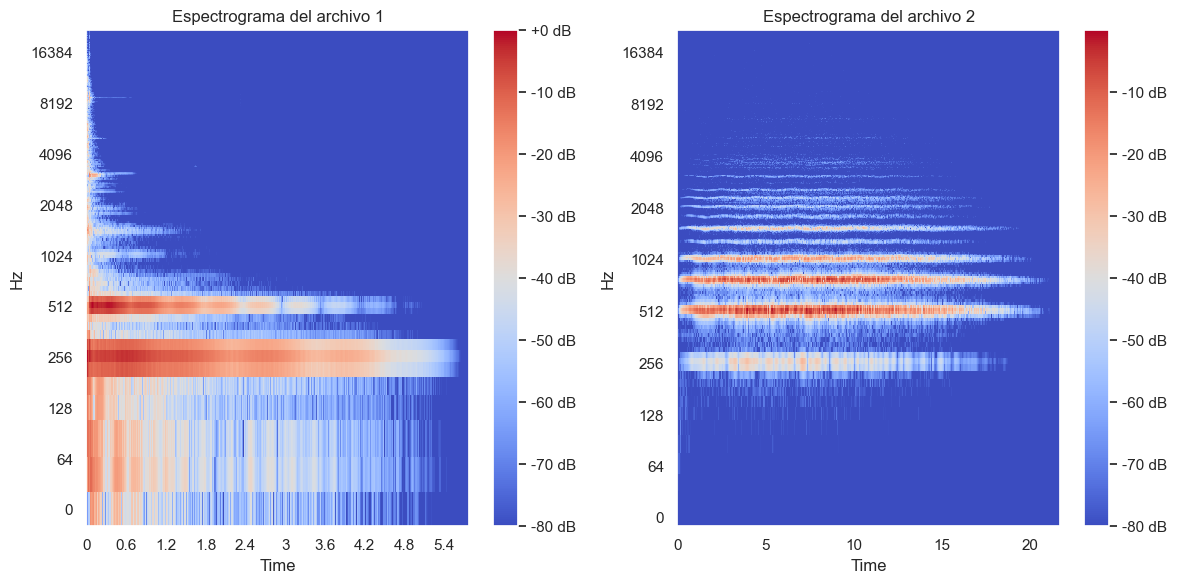

In [52]:
coefs_7 = fourierizer_1(pluck_bell,pad_high,44100,1000,2000,500,500)

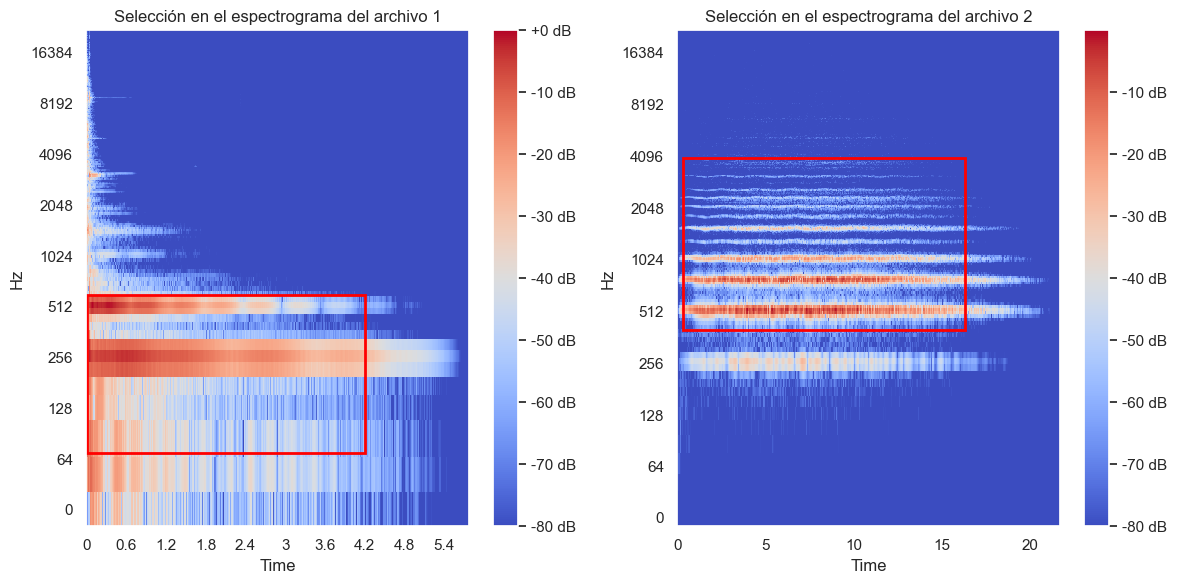

Dimensiones de la matriz 1:  501 ,  510
Dimensiones de la matriz 2:  1001 ,  1914
Duración del sonido 1:  5.7936507936507935 segundos
Duración del sonido 2:  21.73469387755102 segundos
Sonido más corto:  1
Número de columnas en el corte:  511
Dimensiones de la matriz alineada 1:  (501, 511)
Dimensiones de la matriz alineada 2:  (1001, 511)
Matriz modificada en columnas:  1
Matriz modificada en filas:  1
Dimensiones de la matriz final 1:  (1001, 511)
Dimensiones de la matriz final 2:  (1001, 511)


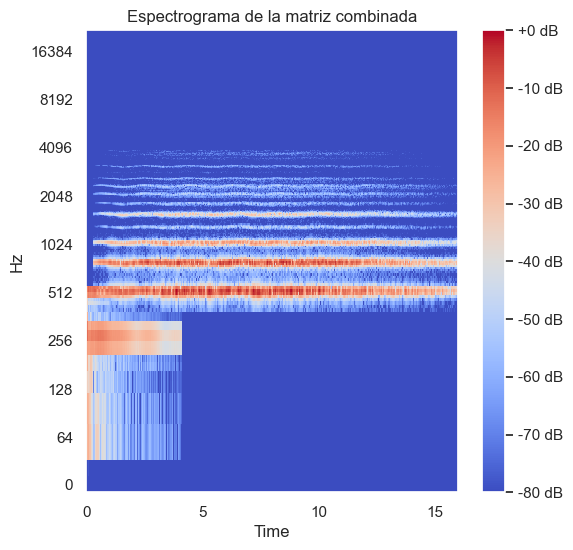

Archivo de audio generadofourierized attack pad.wav


In [65]:
fourierizer_2('fourierized attack pad', coefs_7[0], coefs_7[1], coefs_7[2], coefs_7[3], coefs_7[4], coefs_7[5], coefs_7[6], 0, 0.3, 4.2, 16.0, 70, 400, 600, 4000)

## Ejemplo 8: Kick Acústico X Snare Agudo

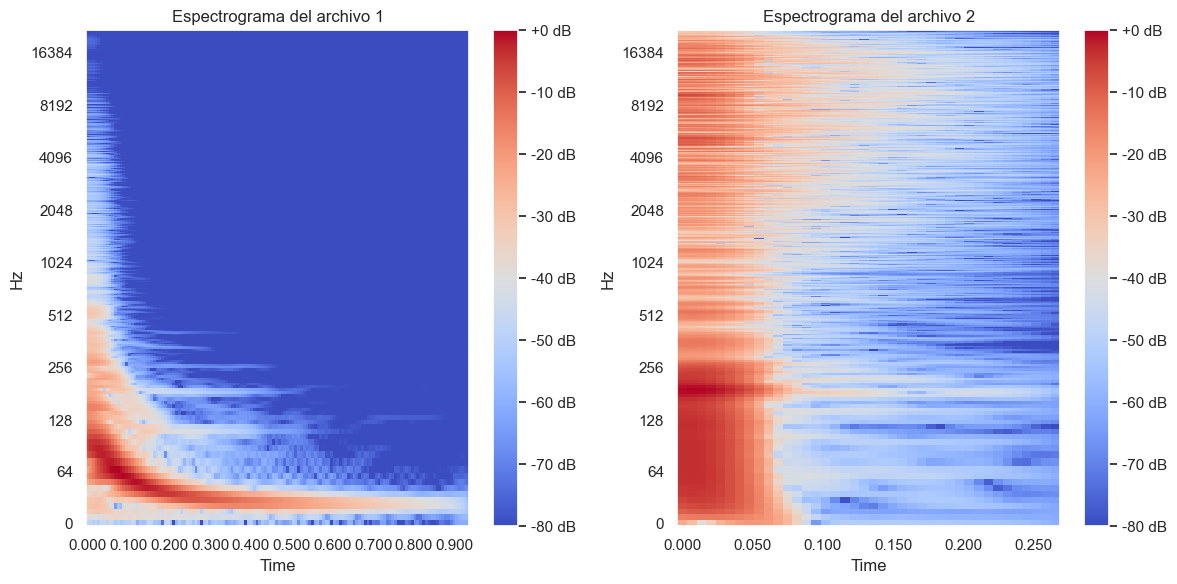

In [56]:
coefs_8 = fourierizer_1(kick_acoustic,snare_high,44100,6000,6000,300,300)

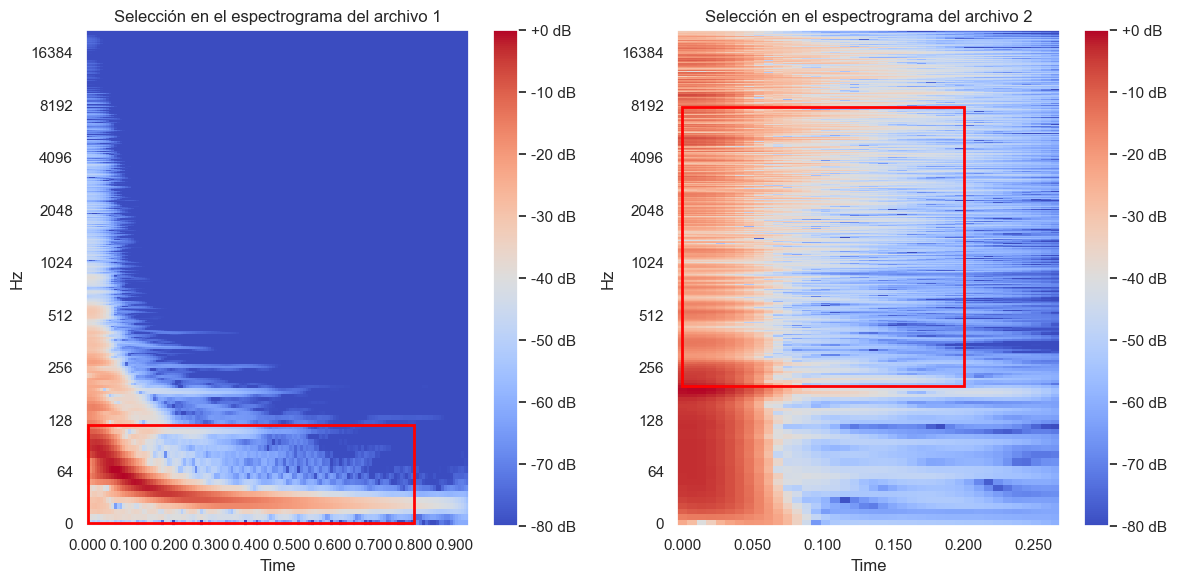

Dimensiones de la matriz 1:  3001 ,  138
Dimensiones de la matriz 2:  3001 ,  40
Duración del sonido 1:  1.0680272108843538 segundos
Duración del sonido 2:  0.4013605442176871 segundos
Sonido más corto:  2
Número de columnas en el corte:  59
Dimensiones de la matriz alineada 1:  (3001, 59)
Dimensiones de la matriz alineada 2:  (3001, 59)
Matriz modificada en columnas:  2
Matriz modificada en filas:  None
Dimensiones de la matriz final 1:  (3001, 59)
Dimensiones de la matriz final 2:  (3001, 59)


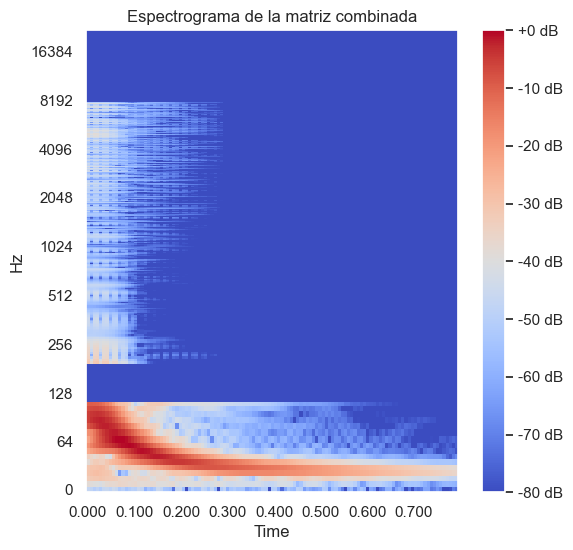

Archivo de audio generadofourierized percussion.wav


In [66]:
fourierizer_2('fourierized percussion', coefs_8[0], coefs_8[1], coefs_8[2], coefs_8[3], coefs_8[4], coefs_8[5], coefs_8[6], 0, 0, 0.8, 0.2, 0, 200, 120, 8000)

In [30]:
audio_1 = kick_acoustic
audio_2 = kick_distorted

In [31]:
# Creación de sliders para los parámetros
Fs_slider = widgets.IntSlider(
    value=44100, min=10025, max=44100, step=1,
    description='F_s (Hz):'
)
w_len_1_slider = widgets.IntSlider(
    value=1024, min=500, max=6000, step=1,
    description='w_len_1:'
)
w_len_2_slider = widgets.IntSlider(
    value=1024, min=500, max=6000, step=1,
    description='w_len_2:'
)
# Los sliders hop se inician con un máximo basado en la mitad de w_len
hop_1_slider = widgets.IntSlider(
    value=512, min=250, max=w_len_1_slider.value//2, step=1,
    description='hop_1:'
)
hop_2_slider = widgets.IntSlider(
    value=512, min=250, max=w_len_2_slider.value//2, step=1,
    description='hop_2:'
)

# Funciones para actualizar dinámicamente el rango máximo de los sliders de hop
def update_hop1_range(change):
    max_hop1 = max(250, change['new'] // 2)
    hop_1_slider.max = max_hop1
    if hop_1_slider.value > max_hop1:
        hop_1_slider.value = max_hop1

def update_hop2_range(change):
    max_hop2 = max(250, change['new'] // 2)
    hop_2_slider.max = max_hop2
    if hop_2_slider.value > max_hop2:
        hop_2_slider.value = max_hop2

w_len_1_slider.observe(update_hop1_range, names='value')
w_len_2_slider.observe(update_hop2_range, names='value')

# Mostrar los sliders
display(Fs_slider, w_len_1_slider, hop_1_slider, w_len_2_slider, hop_2_slider)

# Widgets para seleccionar archivos de audio
file1 = widgets.Text(
    value=audio_1,
    description="Archivo 1:"
)
file2 = widgets.Text(
    value=audio_2,
    description="Archivo 2:"
)
display(file1, file2)

# Botón para ejecutar la función
button = widgets.Button(description="Ejecutar Fourierizer")
output = widgets.Output()
display(button, output)

user_params = None

def on_button_clicked(b):
    global user_params
    with output:
        output.clear_output()
        # Llamar a la función usando los valores de los widgets
        user_params = fourierizer_1(
            file1.value, file2.value, Fs_slider.value,
            w_len_1_slider.value, w_len_2_slider.value,
            hop_1_slider.value, hop_2_slider.value
        )
        print("Procesamiento completado.")

button.on_click(on_button_clicked)

IntSlider(value=44100, description='F_s (Hz):', max=44100, min=10025)

IntSlider(value=1024, description='w_len_1:', max=6000, min=500)

IntSlider(value=512, description='hop_1:', max=512, min=250)

IntSlider(value=1024, description='w_len_2:', max=6000, min=500)

IntSlider(value=512, description='hop_2:', max=512, min=250)

Text(value='C:\\Users\\polo_\\Documents\\Tesis\\Muestras\\Documentadas\\Kick Acústico.wav', description='Archi…

Text(value='C:\\Users\\polo_\\Documents\\Tesis\\Muestras\\Documentadas\\Kick Distorsionado.wav', description='…

Button(description='Ejecutar Fourierizer', style=ButtonStyle())

Output()

In [32]:
# Cargar los audios para calcular sus duraciones (usando F_s proveniente de user_params)
audio1, _ = librosa.load(file1.value, sr=user_params[2])
duration_audio1 = len(audio1) / user_params[2]
if duration_audio1 <= 0.1:
    raise ValueError("El audio 1 es demasiado corto. Debe tener más de 0.1 segundos de duración.")

audio2, _ = librosa.load(file2.value, sr=user_params[2])
duration_audio2 = len(audio2) / user_params[2]
if duration_audio2 <= 0.1:
    raise ValueError("El audio 2 es demasiado corto. Debe tener más de 0.1 segundos de duración.")

# --- Creación de sliders para fourierizer_2 ---

# Slider para asignar el nombre del archivo resultante
sound_name_widget = widgets.Text(
    value="resultado",
    description="Nombre del sonido:"
)

# Sliders para el inicio en segundos (start)
start_1_slider = widgets.FloatSlider(
    value=0.0,
    min=0.0,
    max=duration_audio1 - 0.1,
    step=0.01,
    description='start_1 (s):'
)

start_2_slider = widgets.FloatSlider(
    value=0.0,
    min=0.0,
    max=duration_audio2 - 0.1,
    step=0.01,
    description='start_2 (s):'
)

# Sliders para la duración (duration) con rango dinámico basado en start
duration_1_slider = widgets.FloatSlider(
    value=0.1,
    min=0.1,
    max=duration_audio1 - start_1_slider.value,
    step=0.01,
    description='duration_1 (s):'
)

duration_2_slider = widgets.FloatSlider(
    value=0.1,
    min=0.1,
    max=duration_audio2 - start_2_slider.value,
    step=0.01,
    description='duration_2 (s):'
)

# Funciones para actualizar el rango máximo de duration al cambiar el valor de start
def update_duration1_max(change):
    new_max = duration_audio1 - change['new']
    duration_1_slider.max = new_max
    if duration_1_slider.value > new_max:
        duration_1_slider.value = new_max

def update_duration2_max(change):
    new_max = duration_audio2 - change['new']
    duration_2_slider.max = new_max
    if duration_2_slider.value > new_max:
        duration_2_slider.value = new_max

start_1_slider.observe(update_duration1_max, names='value')
start_2_slider.observe(update_duration2_max, names='value')

# Sliders para frecuencias (mínimas y máximas)
min_freq_1_slider = widgets.IntSlider(
    value=20,
    min=20,
    max=16000,
    step=1,
    description='min_freq_1:'
)

max_freq_1_slider = widgets.IntSlider(
    value=50,
    min=50,
    max=20000,
    step=1,
    description='max_freq_1:'
)

min_freq_2_slider = widgets.IntSlider(
    value=20,
    min=20,
    max=16000,
    step=1,
    description='min_freq_2:'
)

max_freq_2_slider = widgets.IntSlider(
    value=50,
    min=50,
    max=20000,
    step=1,
    description='max_freq_2:'
)

# Mostrar los widgets de los parámetros
display(sound_name_widget, 
        start_1_slider, duration_1_slider, min_freq_1_slider, max_freq_1_slider,
        start_2_slider, duration_2_slider, min_freq_2_slider, max_freq_2_slider)

# Botón para ejecutar la función fourierizer_2
button2 = widgets.Button(description="Ejecutar Fourierizer 2")
output2 = widgets.Output()
display(button2, output2)

def on_button2_clicked(b):
    with output2:
        output2.clear_output()
        # Extraer los parámetros fijos guardados en user_params
        stft_1, stft_2, F_s, w_len_1, w_len_2, hop_1, hop_2 = user_params
        
        # Llamar a la función fourierizer_2 con todos los parámetros
        result2 = fourierizer_2(
            sound_name_widget.value,
            stft_1, stft_2, F_s, w_len_1, w_len_2, hop_1, hop_2,
            start_1_slider.value, start_2_slider.value,
            duration_1_slider.value, duration_2_slider.value,
            min_freq_1_slider.value, min_freq_2_slider.value,
            max_freq_1_slider.value, max_freq_2_slider.value
        )
        print("Procesamiento de Fourierizer 2 completado.")

button2.on_click(on_button2_clicked)

Text(value='resultado', description='Nombre del sonido:')

FloatSlider(value=0.0, description='start_1 (s):', max=0.8375056689342404, step=0.01)

FloatSlider(value=0.1, description='duration_1 (s):', max=0.9375056689342404, min=0.1, step=0.01)

IntSlider(value=20, description='min_freq_1:', max=16000, min=20)

IntSlider(value=50, description='max_freq_1:', max=20000, min=50)

FloatSlider(value=0.0, description='start_2 (s):', max=2.914421768707483, step=0.01)

FloatSlider(value=0.1, description='duration_2 (s):', max=3.014421768707483, min=0.1, step=0.01)

IntSlider(value=20, description='min_freq_2:', max=16000, min=20)

IntSlider(value=50, description='max_freq_2:', max=20000, min=50)

Button(description='Ejecutar Fourierizer 2', style=ButtonStyle())

Output()